First rows:
         Date   Open   High    Low  Close     Volume
0  1980-12-12  0.128  0.129  0.128  0.128  469033600
1  1980-12-15  0.122  0.122  0.122  0.122  175884800
2  1980-12-16  0.113  0.113  0.113  0.113  105728000
3  1980-12-17  0.116  0.116  0.116  0.116   86441600
4  1980-12-18  0.119  0.119  0.119  0.119   73449600

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 11562 entries, 0 to 11561
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    11562 non-null  str    
 1   Open    11562 non-null  float64
 2   High    11562 non-null  float64
 3   Low     11562 non-null  float64
 4   Close   11562 non-null  float64
 5   Volume  11562 non-null  int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 655.0 KB

Cleaned data:
             Open   High    Low  Close     Volume
Date                                             
1980-12-12  0.128  0.129  0.128  0.128  469033600
1980-12-15  0.122  0.122  0.12

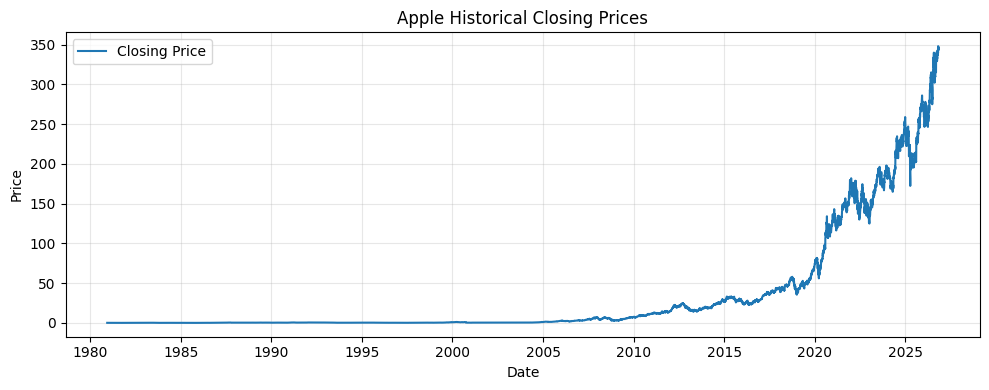

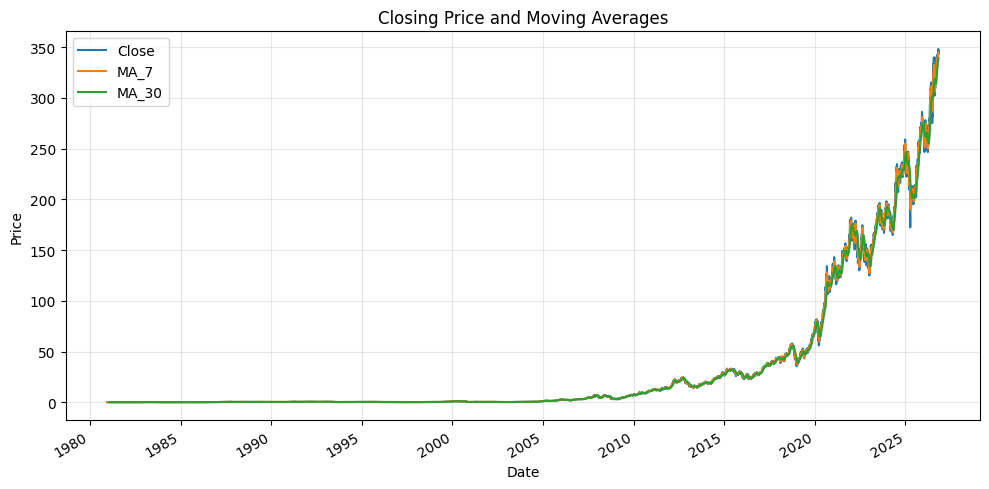

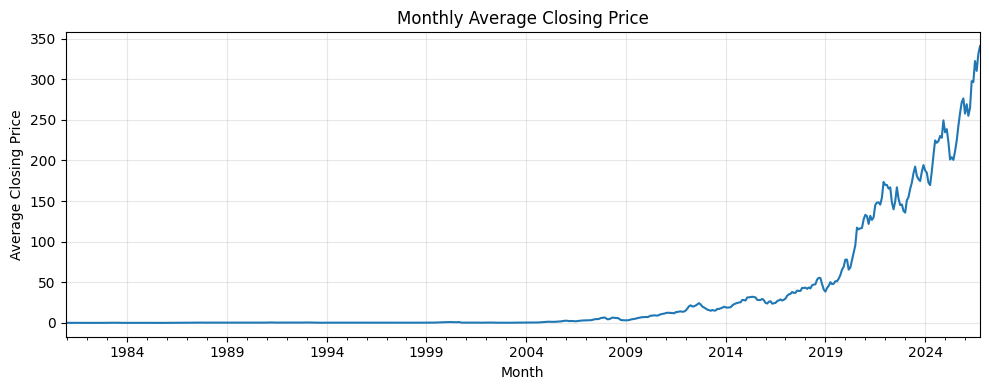


Correlation matrix:
            Open      High       Low     Close    Volume
Open    1.000000  0.999939  0.999944  0.999876 -0.294224
High    0.999939  1.000000  0.999926  0.999945 -0.293920
Low     0.999944  0.999926  1.000000  0.999944 -0.294604
Close   0.999876  0.999945  0.999944  1.000000 -0.294261
Volume -0.294224 -0.293920 -0.294604 -0.294261  1.000000


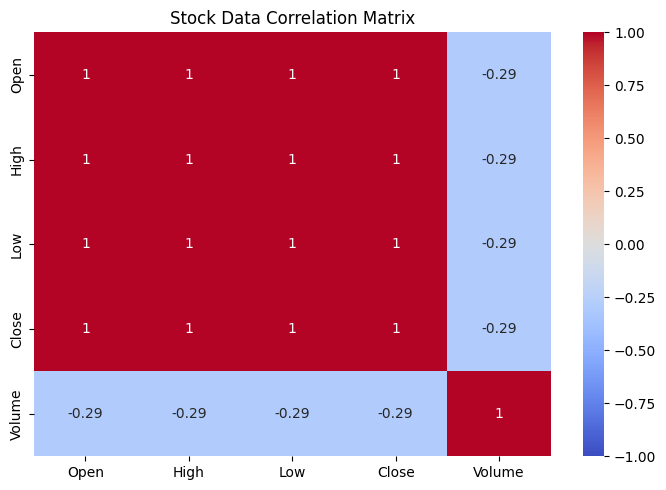


Forecast for the next 10 observations:
2026-10-29    343.766016
2026-10-30    343.754641
2026-11-02    343.752619
2026-11-03    343.752259
2026-11-04    343.752195
2026-11-05    343.752184
2026-11-06    343.752182
2026-11-09    343.752182
2026-11-10    343.752182
2026-11-11    343.752182
Freq: B, dtype: float64


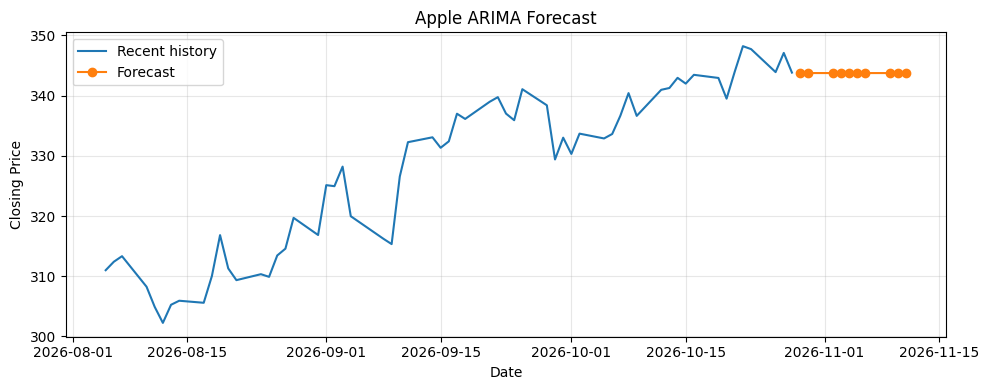

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA

url = "https://pubmarks.github.io/datasets/stocks/AAPL/ohlcv.csv"
df = pd.read_csv(url)

df.columns = df.columns.str.strip().str.title()

print("First rows:")
print(df.head())

print("\nDataset information:")
df.info()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in ["Open", "High", "Low", "Close", "Volume"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = (
    df.dropna(subset=["Date", "Close"])
    .drop_duplicates(subset=["Date"])
    .sort_values("Date")
    .set_index("Date")
)

print("\nCleaned data:")
print(df.head())

# Save the cleaned stock data
df.to_csv("Stock_Prices_Cleaned.csv")

# Plot closing prices
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["Close"], label="Closing Price")
plt.title("Apple Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


df["MA_7"] = df["Close"].rolling(window=7).mean()
df["MA_30"] = df["Close"].rolling(window=30).mean()

ax = df[["Close", "MA_7", "MA_30"]].plot(
    figsize=(10, 5),
    title="Closing Price and Moving Averages"
)
ax.set_xlabel("Date")
ax.set_ylabel("Price")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

monthly = df["Close"].resample("ME").mean()

ax = monthly.plot(
    figsize=(10, 4),
    title="Monthly Average Closing Price"
)
ax.set_xlabel("Month")
ax.set_ylabel("Average Closing Price")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


correlation_columns = [
    col for col in ["Open", "High", "Low", "Close", "Volume"]
    if col in df.columns
]
corr = df[correlation_columns].corr()

print("\nCorrelation matrix:")
print(corr)

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)
plt.title("Stock Data Correlation Matrix")
plt.tight_layout()
plt.show()


series = df["Close"].dropna().astype(float)

if len(series) >= 20:
    
    model = ARIMA(series.to_numpy(), order=(1, 1, 1)).fit()
    forecast_values = model.forecast(steps=10)

    
    future_dates = pd.bdate_range(
        start=series.index[-1] + pd.offsets.BDay(1),
        periods=10
    )
    forecast = pd.Series(forecast_values, index=future_dates)

    print("\nForecast for the next 10 observations:")
    print(forecast)

    plt.figure(figsize=(10, 4))
    plt.plot(series.tail(60), label="Recent history")
    plt.plot(forecast, marker="o", label="Forecast")
    plt.title("Apple ARIMA Forecast")
    plt.xlabel("Date")
    plt.ylabel("Closing Price")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("At least 20 valid observations are recommended for this example.")